## Load the preprocessed KDEF data


In [2]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

with open("data/kdef_preprocessed.pkl", "rb") as file:
    data = pickle.load(file)
required_keys = ["X_train_kdef", "y_train_kdef", "X_test_kdef", "y_test_kdef",
                 "train_subject_ids", "test_subject_ids", "train_paths", "test_paths"]
missing = [key for key in required_keys if key not in data]
if missing:
    raise ValueError("Run the updated KDEF preprocessing cell first. Missing fields: " + ", ".join(missing))
X_train_images = data["X_train_kdef"]
y_train = np.asarray(data["y_train_kdef"], dtype=str)
X_test_images = data["X_test_kdef"]
y_test = np.asarray(data["y_test_kdef"], dtype=str)

## Extract Facial Landmarks

Landmark shape: (68, 2)


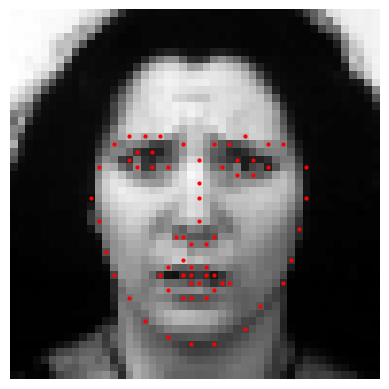

In [4]:
import dlib

shape_predict = dlib.shape_predictor("faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat")

image_shape = np.asarray(X_train_images[0]).copy()

# Convert floating-point pixels from [0, 1] to [0, 255] if required
if np.issubdtype(image_shape.dtype, np.floating) and image_shape.max() <= 1.0:
    image_shape = image_shape * 255

image_shape = np.clip(image_shape, 0, 255).astype(np.uint8)


image_bound = dlib.rectangle(0, 0, image_shape.shape[1]-1, image_shape.shape[0]-1)  
shape = shape_predict(image_shape, image_bound)
points = np.array([[p.x, p.y] for p in shape.parts()])

print("Landmark shape:", points.shape)

plt.imshow(image_shape, cmap="gray")
plt.scatter(points[:, 0], points[:, 1], c="red", s=4)
plt.axis("off")
plt.show()

We use dlib to find 68 points around the eyes, eyebrows, mouth, nose, and face outline. We use these coordinates to calculate seven geometric features.

## Calculate seven geometric features

The features describe eye opening, mouth opening, inner mouth width, eyebrow-to-eye position, mouth curvature, left-right brow height difference, and inner brow distance. Ratios reduce the effect of face size.

`brow_slant` is kept as a code name, but it measures the height difference between the left and right brows, not the slope of each brow. Its sign indicates which selected brow point is lower in the image.

`eyebrow_gap` uses eyebrow y minus eye y. It is usually negative; a higher value means a smaller vertical gap. `smile_curvature` compares the mouth corners with the upper-lip midpoint. A higher value does not automatically mean a stronger smile. These limits matter when interpreting the rules.

In [5]:
def geometric_facial_features(points):
    points = np.asarray(points, dtype=float)

    def distance(i, j):
        return float(np.linalg.norm(points[i] - points[j]))

    def safe_ratio(numerator, denominator):
        if not np.isfinite(denominator) or denominator <= 0:
            return np.nan
        return numerator / denominator

    face_width = distance(0, 16)
    inter_eye_dist = distance(36, 45)

    # Eye opening
    left_eye_width = distance(36, 39)
    right_eye_width = distance(42, 45)

    left_eye = safe_ratio(
        distance(37, 41) + distance(38, 40),
        2 * left_eye_width
    )
    right_eye = safe_ratio(
        distance(43, 47) + distance(44, 46),
        2 * right_eye_width
    )

    eye_opening = np.mean([left_eye, right_eye])

    # Mouth measurements
    inner_mouth_width_px = distance(60, 64)

    mouth_vertical_opening = np.mean([
        abs(points[61, 1] - points[67, 1]),
        abs(points[62, 1] - points[66, 1]),
        abs(points[63, 1] - points[65, 1])
    ])

    # Normalize width by face width
    inner_mouth_width = safe_ratio(
        inner_mouth_width_px, face_width
    )

    # Normalize opening by inner mouth width
    mouth_opening = safe_ratio(
        mouth_vertical_opening, inner_mouth_width_px
    )

    # Smile curvature
    smile_curvature = safe_ratio(
        np.mean(points[[48, 54], 1]) - points[51, 1],
        distance(48, 54)
    )

    # Eyebrow-to-eye gap
    eyebrow_gap = safe_ratio(
        np.mean(points[[19, 24], 1]) -
        np.mean(points[[37, 44], 1]),
        face_width
    )

    # Brow slant
    eyebrow_slant = safe_ratio(
        points[19, 1] - points[24, 1],
        distance(19, 24)
    )

    # Inner eyebrow distance
    inner_brow_distance = safe_ratio(
        distance(21, 22), inter_eye_dist
    )

    features_names = {
        "eye_opening": eye_opening,
        "mouth_opening": mouth_opening,
        "inner_mouth_width": inner_mouth_width,
        "eyebrow_gap": eyebrow_gap,
        "smile_curvature": smile_curvature,
        "brow_slant": eyebrow_slant,
        "inner_brow_distance": inner_brow_distance
    }

    return features_names



## Check saved subject IDs

In [6]:
train_subject_ids = np.asarray(data["train_subject_ids"], dtype=str)
test_subject_ids = np.asarray(data["test_subject_ids"], dtype=str)
assert len(X_train_images) == len(y_train) == len(train_subject_ids) == len(data["train_paths"])
assert len(X_test_images) == len(y_test) == len(test_subject_ids) == len(data["test_paths"])
assert set(train_subject_ids).isdisjoint(set(test_subject_ids))
print("Train subjects:", len(np.unique(train_subject_ids)))
print("Test subjects:", len(np.unique(test_subject_ids)))

Train subjects: 56
Test subjects: 14


## Create a subject-independent validation split

We reserve 20% of the training subjects for validation. Sessions A and B of each person stay together. The test subjects remain separate.

In [8]:
from sklearn.model_selection import train_test_split

train_df = train_subject_ids

unique_subjects = np.unique(train_df)


fuzzy_trained_subjects, val_subjects = train_test_split(unique_subjects, test_size=0.2, random_state=42)

fuzzy_train_id = np.flatnonzero(np.isin(train_df, fuzzy_trained_subjects))
val_id = np.flatnonzero(np.isin(train_df, val_subjects))

X_fuzzy_train = X_train_images[fuzzy_train_id]
y_fuzzy_train = y_train[fuzzy_train_id]
X_val = X_train_images[val_id]  
y_val = y_train[val_id]

assert set(fuzzy_trained_subjects).isdisjoint(set(val_subjects))


print("Fuzzy train subjects:", np.unique(fuzzy_trained_subjects).size)
print("Validation subjects:", np.unique(val_subjects).size)
print("Fuzzy train samples:", len(X_fuzzy_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test_images))
assert set(fuzzy_trained_subjects).isdisjoint(set(test_subject_ids))
assert set(val_subjects).isdisjoint(set(test_subject_ids))

Fuzzy train subjects: 44
Validation subjects: 12
Fuzzy train samples: 616
Validation samples: 168
Test samples: 196


## Extract features for training and validation images

In [9]:
# Define feature names BEFORE calling the extractor
feature_names = [
    "eye_opening",
    "mouth_opening",
    "inner_mouth_width",
    "eyebrow_gap",
    "smile_curvature",
    "brow_slant",
    "inner_brow_distance"
]

def extract_geometric_features(images):
    features_list = []
    for i, img in enumerate(images, start=1):

        img = np.asarray(img).copy()

        if np.issubdtype(img.dtype, np.floating) and img.max() <= 1.0:
            img = img * 255

        img_uint8 = np.clip(img, 0, 255).astype(np.uint8)
        img_bound = dlib.rectangle(0, 0, img_uint8.shape[1]-1, img_uint8.shape[0]-1)
        shape = shape_predict(img_uint8, img_bound)
        points = np.array([[p.x, p.y] for p in shape.parts()])
        features = geometric_facial_features(points)

        features_list.append([features[name] for name in feature_names])

        if i % 100 == 0 or i == len(images):
            print(f"Processed {i}/{len(images)} images")

    return np.asanyarray(features_list, dtype=float)


X_train_fuzzy = extract_geometric_features(X_fuzzy_train)
X_val_fuzzy = extract_geometric_features(X_val)

print("Fuzzy training features: ", X_train_fuzzy.shape)
print("Validation features: ", X_val_fuzzy.shape)
print("All values finite: ", np.isfinite(X_train_fuzzy).all() and np.isfinite(X_val_fuzzy).all())
print("Number of feature names:", len(feature_names))
print("Training matrix shape:", X_train_fuzzy.shape)

pd.DataFrame(X_train_fuzzy, columns=feature_names).head().round(3)

Processed 100/616 images
Processed 200/616 images
Processed 300/616 images
Processed 400/616 images
Processed 500/616 images
Processed 600/616 images
Processed 616/616 images
Processed 100/168 images
Processed 168/168 images
Fuzzy training features:  (616, 7)
Validation features:  (168, 7)
All values finite:  True
Number of feature names: 7
Training matrix shape: (616, 7)


,eye_opening,mouth_opening,inner_mouth_width,eyebrow_gap,smile_curvature,brow_slant,inner_brow_distance
0,0.180,0.267,0.322,-0.129,0.083,-0.062,0.262
1,0.250,0.000,0.233,-0.117,0.100,-0.067,0.217
2,0.248,0.000,0.266,-0.133,0.055,-0.067,0.315
3,0.404,0.083,0.401,-0.133,0.036,0.000,0.316
4,0.247,0.000,0.292,-0.145,0.091,0.062,0.250


## Set fuzzy-term boundaries

For six features, we use training-data quartiles to define Low, Medium, and High. For `brow_slant`, we keep the fixed scale of 0.10 around zero. This is a chosen setting, not a value learned from the test set.

In [10]:
membership_thresholds = {}

for i, name in enumerate(feature_names):
    q25, q50, q75 = np.percentile(
        X_train_fuzzy[:, i],
        [25, 50, 75]
    )

    membership_thresholds[name] = {
        "q25": q25,
        "q50": q50,
        "q75": q75
    }

    print(
        f"{name:22s}: "
        f"q25={q25:.4f}, q50={q50:.4f}, q75={q75:.4f}"
    )

eye_opening           : q25=0.2385, q50=0.3311, q75=0.4077
mouth_opening         : q25=0.0458, q50=0.1250, q75=0.2481
inner_mouth_width     : q25=0.2489, q50=0.2769, q75=0.3145
eyebrow_gap           : q25=-0.1407, q50=-0.1129, q75=-0.0937
smile_curvature       : q25=0.0833, q50=0.1358, q75=0.2222
brow_slant            : q25=0.0000, q50=0.0000, q75=0.0624
inner_brow_distance   : q25=0.2349, q50=0.2774, q75=0.3065


## Convert Feature values to fuzzy memberships 

In [11]:
def fuzzify(feature_matrix):
    feature_matrix = np.asarray(feature_matrix, dtype=float)

    n_samples, n_features = feature_matrix.shape

    if n_features != len(feature_names):
        raise ValueError(
            f"Expected {len(feature_names)} features, "
            f"but received {n_features}."
        )

    memberships = np.zeros((n_samples, n_features, 3), dtype=float)

    for j, name in enumerate(feature_names):
        x = feature_matrix[:, j]

        if name == "brow_slant":
            # Negative = Low, near zero = Medium, positive = High
            low = np.clip(-x / 0.10, 0, 1)
            high = np.clip(x / 0.10, 0, 1)
            medium = 1 - np.maximum(low, high)

        else:
            #q25, q50, q75 = membership_thresholds[name]
            q25 = float(membership_thresholds[name]["q25"])
            q50 = float(membership_thresholds[name]["q50"])
            q75 = float(membership_thresholds[name]["q75"])

            # Low membership
            if q50 > q25:
                low = np.clip((q50 - x) / (q50 - q25), 0, 1)
            else:
                low = (x <= q50).astype(float)

            # High membership
            if q75 > q50:
                high = np.clip((x - q50) / (q75 - q50), 0, 1)
            else:
                high = (x > q50).astype(float)

            # Medium membership
            medium = 1 - np.maximum(low, high)

        memberships[:, j, :] = np.column_stack(
            (low, medium, high)
        )

    return memberships


# Use the extracted geometric features, NOT the 48x48 images
X_fuzzy_train = X_train_fuzzy
X_fuzzy_val = X_val_fuzzy

# Calculate memberships
train_memberships = fuzzify(X_fuzzy_train)
val_memberships = fuzzify(X_fuzzy_val)

print("Training memberships:", train_memberships.shape)
print("Validation memberships:", val_memberships.shape)

print(
    "Largest deviation from sum 1:",
    np.max(
        np.abs(train_memberships.sum(axis=2) - 1)
    ).round(6)

)

terms = ["Low", "Medium", "High"]

display(
    pd.DataFrame(
        train_memberships[0],
        index=feature_names,
        columns=terms
    ).round(3)
)

Training memberships: (616, 7, 3)
Validation memberships: (168, 7, 3)
Largest deviation from sum 1: 0.0


,Low,Medium,High
eye_opening,1.000,0.000,0.0
mouth_opening,0.000,0.000,1.0
inner_mouth_width,0.000,0.000,1.0
eyebrow_gap,0.579,0.421,0.0
smile_curvature,1.000,0.000,0.0
brow_slant,0.624,0.376,0.0
inner_brow_distance,0.368,0.632,0.0


## Learn fuzzy emotion rules



In [12]:
from itertools import product

emotion_names = sorted(str(label) for label in np.unique(y_fuzzy_train))
emotion_to_index = {
    emotion: i for i, emotion in enumerate(emotion_names)
}

candidate_counts = {}

for i, label in enumerate(y_fuzzy_train):
    label_index = emotion_to_index[str(label)]

    for terms in product(range(3), repeat=len(feature_names)):
        strength = min(
            train_memberships[i, feature_index, term]
            for feature_index, term in enumerate(terms)
        )

        if strength == 0:
            continue

        if terms not in candidate_counts:
            candidate_counts[terms] = np.zeros(len(emotion_names))

        candidate_counts[terms][label_index] += strength


minimum_support = 1.0
rules = []

for terms, class_counts in candidate_counts.items():
    support = class_counts.sum()

    if support < minimum_support:
        continue

    prediction_index = int(np.argmax(class_counts))
    probabilities = (class_counts + 1) / (support + len(emotion_names))

    term_names = ["Low", "Medium", "High"]
    conditions = " AND ".join(
        f"{name} is {term_names[term]}"
        for name, term in zip(feature_names, terms)
    )

    rules.append({
        "terms": terms,
        "prediction": emotion_names[prediction_index],
        "support": support,
        "confidence": class_counts[prediction_index] / support,
        "probabilities": probabilities,
        "rule": (
            f"IF {conditions} THEN emotion is "
            f"{emotion_names[prediction_index]}"
        ),
    })

rules_df = pd.DataFrame(rules).sort_values(
    ["support", "confidence"], ascending=False
)

print("Number of learned rules:", len(rules_df))
rules_df[["rule", "support", "confidence"]].head(10).round(3)
for _, row in rules_df.head(5).iterrows():
    print(row["rule"])
    print(f"Weighted support: {row['support']:.2f}; training confidence: {row['confidence']:.2f}\n")

Number of learned rules: 621
IF eye_opening is High AND mouth_opening is High AND inner_mouth_width is Low AND eyebrow_gap is Low AND smile_curvature is High AND brow_slant is Medium AND inner_brow_distance is High THEN emotion is surprise
Weighted support: 16.75; training confidence: 0.83

IF eye_opening is High AND mouth_opening is High AND inner_mouth_width is Medium AND eyebrow_gap is Low AND smile_curvature is High AND brow_slant is Medium AND inner_brow_distance is High THEN emotion is surprise
Weighted support: 12.56; training confidence: 0.79

IF eye_opening is Low AND mouth_opening is Medium AND inner_mouth_width is High AND eyebrow_gap is Low AND smile_curvature is Low AND brow_slant is Medium AND inner_brow_distance is High THEN emotion is happy
Weighted support: 8.57; training confidence: 0.54

IF eye_opening is High AND mouth_opening is High AND inner_mouth_width is Low AND eyebrow_gap is High AND smile_curvature is High AND brow_slant is Medium AND inner_brow_distance is 

## Predict and evaluate on validation data


In [13]:
from matplotlib import cm
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    confusion_matrix
)

def predict_fuzzy(rules, memberships, classes):
    predictions = []

    for sample in memberships:
        class_scores = {label: 0.0 for label in classes}
        for rule in rules:
            terms = rule["terms"]
            # Minimum membership across all seven conditions
            strength = np.min(sample[np.arange(sample.shape[0]), terms])
            if strength <= 0:
                continue
            # Weight each rule by its confidence
            class_scores[rule["prediction"]] += (strength * rule["confidence"])

        if max(class_scores.values()) == 0:
            predictions.append(None)
        else:
            predictions.append(max(class_scores, key=class_scores.get))

    return np.asarray(predictions, dtype=object)


classes = np.unique(y_fuzzy_train)

def evaluate_fuzzy(y_true, predictions, title):
    from sklearn.metrics import recall_score
    y_true = np.asarray(y_true, dtype=str)
    y_eval = np.asarray(["No prediction" if p is None else str(p) for p in predictions])
    covered = y_eval != "No prediction"
    metrics = {
        "Accuracy": accuracy_score(y_true, y_eval),
        "Balanced accuracy": recall_score(y_true, y_eval, labels=classes,
                                         average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_eval, labels=classes,
                             average="macro", zero_division=0),
        "Coverage": covered.mean(),
        "No prediction count": int((~covered).sum())
    }
    print(title)
    print(pd.Series(metrics).to_string())
    print(classification_report(y_true, y_eval, labels=classes, zero_division=0))
    return y_eval, metrics

def plot_fuzzy_confusion(y_true, y_eval, title):
    labels = list(classes) + ["No prediction"]
    matrix = confusion_matrix(y_true, y_eval, labels=labels)[:len(classes), :]
    assert matrix.sum() == len(y_true)
    plt.figure(figsize=(10, 6))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=classes)
    plt.xlabel("Predicted emotion")
    plt.ylabel("Actual emotion")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return matrix

y_val_pred = predict_fuzzy(rules, val_memberships, classes)
y_val_array = np.asarray(y_val, dtype=str)
y_val_eval, validation_metrics = evaluate_fuzzy(y_val_array, y_val_pred, "Validation results")

Validation results
Accuracy               0.398810
Balanced accuracy      0.398810
Macro F1               0.381222
Coverage               0.976190
No prediction count    4.000000
              precision    recall  f1-score   support

      afraid       0.36      0.21      0.26        24
       angry       0.52      0.50      0.51        24
     disgust       0.12      0.08      0.10        24
       happy       0.58      0.75      0.65        24
     neutral       0.23      0.29      0.26        24
         sad       0.28      0.21      0.24        24
    surprise       0.56      0.75      0.64        24

   micro avg       0.41      0.40      0.40       168
   macro avg       0.38      0.40      0.38       168
weighted avg       0.38      0.40      0.38       168



## Confusion Matrix

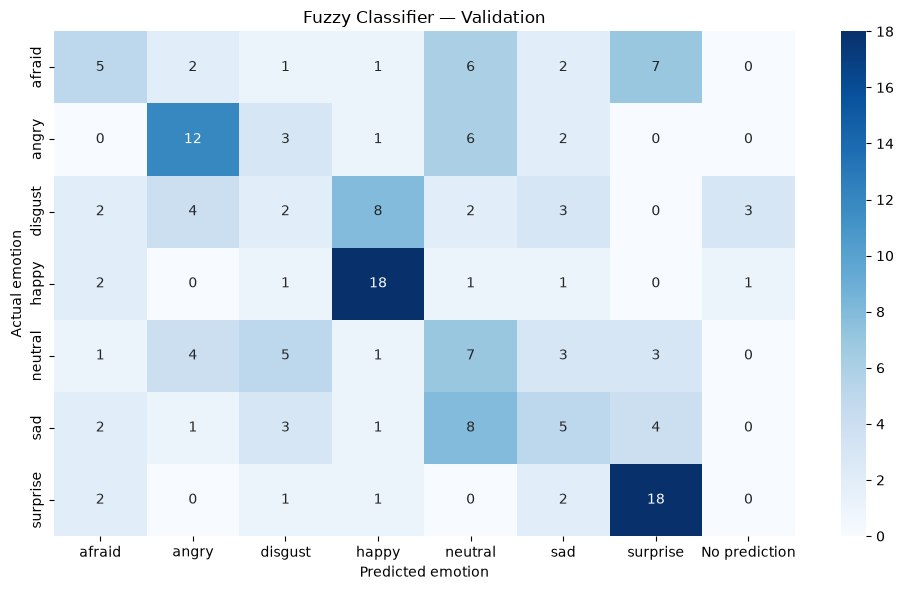

In [14]:
validation_cm = plot_fuzzy_confusion(y_val_array, y_val_eval, "Fuzzy Classifier — Validation")

## Final evaluation on held-out KDEF test subjects

We use all test images. If no rule fires, the model returns no prediction. That image still counts as an error in accuracy and recall. We report coverage separately. Macro F1 averages only the seven emotion classes. No test labels are used to change the rules.

Processed 100/196 images
Processed 196/196 images
Test results
Accuracy               0.418367
Balanced accuracy      0.418367
Macro F1               0.405831
Coverage               0.959184
No prediction count    8.000000
              precision    recall  f1-score   support

      afraid       0.24      0.18      0.20        28
       angry       0.53      0.36      0.43        28
     disgust       0.47      0.29      0.36        28
       happy       0.62      0.75      0.68        28
     neutral       0.38      0.46      0.42        28
         sad       0.33      0.18      0.23        28
    surprise       0.42      0.71      0.53        28

   micro avg       0.44      0.42      0.43       196
   macro avg       0.43      0.42      0.41       196
weighted avg       0.43      0.42      0.41       196



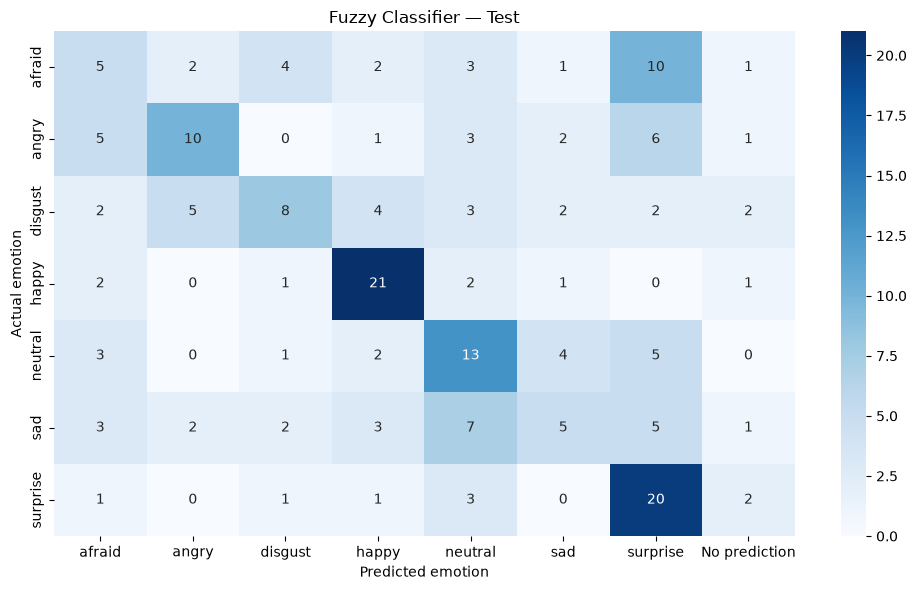

Saved results and fuzzy model settings.


In [15]:
X_test_fuzzy = extract_geometric_features(X_test_images)
assert np.isfinite(X_test_fuzzy).all(), "Test features contain missing or invalid values."
test_memberships = fuzzify(X_test_fuzzy)
y_test_pred = predict_fuzzy(rules, test_memberships, classes)
y_test_array = np.asarray(y_test, dtype=str)
y_test_eval, test_metrics = evaluate_fuzzy(y_test_array, y_test_pred, "Test results")
test_cm = plot_fuzzy_confusion(y_test_array, y_test_eval, "Fuzzy Classifier — Test")

from pathlib import Path
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
pd.DataFrame([validation_metrics, test_metrics], index=["Validation", "Test"]).to_csv(
    results_dir / "fuzzy_metrics.csv", index_label="Split")
rules_df[["rule", "support", "confidence", "prediction"]].to_csv(
    results_dir / "fuzzy_rules.csv", index=False)
pd.DataFrame(test_cm, index=classes, columns=list(classes) + ["No prediction"]).to_csv(
    results_dir / "fuzzy_test_confusion.csv")

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)
with open(model_dir / "fuzzy_kdef_model.pkl", "wb") as file:
    pickle.dump({"rules": rules, "feature_names": feature_names,
                 "membership_thresholds": membership_thresholds, "classes": classes,
                 "brow_slant_scale": 0.10,
                 "landmark_predictor_path": "faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat"}, file)
print("Saved results and fuzzy model settings.")

## Fuzzy Classifier Results

| Metric | Validation set | Test set |
|---|---:|---:|
| Images | 168 | 196 |
| Subjects | 12 | 14 |
| Accuracy | 39.88% | 41.84% |
| Balanced accuracy | 39.88% | 41.84% |
| Macro F1 | 0.3812 | 0.4058 |
| Prediction coverage | 97.62% | 95.92% |
| Images without a prediction | 4 | 8 |

Images without a prediction are included in the evaluation
and counted as errors.

### Test Results by Emotion

| Emotion | Precision | Recall | F1-score | Images |
|---|---:|---:|---:|---:|
| Afraid | 0.24 | 0.18 | 0.20 | 28 |
| Angry | 0.53 | 0.36 | 0.43 | 28 |
| Disgust | 0.47 | 0.29 | 0.36 | 28 |
| Happy | 0.62 | 0.75 | 0.68 | 28 |
| Neutral | 0.38 | 0.46 | 0.42 | 28 |
| Sad | 0.33 | 0.18 | 0.23 | 28 |
| Surprise | 0.42 | 0.71 | 0.53 | 28 |

Happy and surprise had the highest recall. Afraid and sad
were the hardest to recognize. Each emotion had the same
number of test images, so accuracy and balanced accuracy
were equal.